In [3]:
# ==========================================================
# CELDA DE RESOLUCIÓN DE DEPENDENCIAS (Ejecutar solo si hay conflictos con NumPy 2)
# ==========================================================
# Si al importar obtienes incompatibilidades con NumPy 2 / pandas 3 / opencv 5,
# descomenta las siguientes dos líneas, ejecuta la celda y REINICIA el kernel:
#
# !pip uninstall -y opencv-python opencv-python-headless
# !pip install "numpy==1.26.4" "pandas<2.3" "opencv-python==4.10.0.84"



In [ ]:
import os
import json
import random
import shutil
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from ultralytics import YOLO

# ==========================================================
# 1. SEMILLA ALEATORIA PARA REPRODUCIBILIDAD
# ==========================================================
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# ==========================================================
# 2. DETECCIÓN AUTOMÁTICA DE ACELERADOR HARDWARE
# ==========================================================
if torch.cuda.is_available():
    DEVICE = 0
    device_desc = f"NVIDIA GPU ({torch.cuda.get_device_name(0)})"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
    device_desc = "Apple Silicon GPU (MPS)"
else:
    DEVICE = "cpu"
    device_desc = "CPU"

print(f"✓ Semilla fijada en: {SEED}")
print(f"✓ PyTorch versión: {torch.__version__}")
print(f"✓ OpenCV versión: {cv2.__version__}")
print(f"✓ Ultralytics YOLO cargado")
print(f"✓ Acelerador activo: {DEVICE} ({device_desc})")

# ==========================================================
# 3. VERIFICACIÓN DE INTEGRACIÓN TORCH <-> NUMPY
# ==========================================================
try:
    _test_tensor = torch.from_numpy(np.zeros(1))
    print(f"✓ NumPy versión: {np.__version__} (integración con PyTorch OK)")
except RuntimeError as err:
    print(f"\n❌ ERROR CRÍTICO TORCH-NUMPY: {err}")
    print(f"   Estás ejecutando NumPy {np.__version__} con PyTorch {torch.__version__}.")
    print("   PyTorch 2.2.2 no es compatible con NumPy 2.x o requiere reiniciar el kernel.")
    print("   Solución: instala numpy 1.26.4 y REINICIA el kernel de Jupyter.")
    raise err


✓ Semilla fijada en: 42
✓ PyTorch versión: 2.6.0+cu124
✓ OpenCV versión: 4.10.0
✓ Ultralytics YOLO cargado
✓ Acelerador activo: 0 (NVIDIA GPU (NVIDIA GeForce RTX 3060 Ti))
✓ NumPy versión: 1.26.4 (integración con PyTorch OK)


---
## 2. Cargador de Datos y Verificación de Integridad

El dataset en `image-dataset/prac4VC_dataset` contiene dos carpetas:
- `images/`: Imágenes de vehículos en formato JPEG (pudiendo tener extensiones `.jpg`, `.jpeg`, o en mayúsculas `.JPG`).
- `annotations/`: Ficheros JSON homónimos con la lista de anotaciones:
  ```json
  [
      {
          "rectangle": [x_center, y_center, width, height],
          "plate": "0000AAA"
      }
  ]
  ```

### Requisitos implementados en el cargador:
1. **Comprobación 1 a 1 de anotaciones**: Cada imagen debe tener cargada su correspondiente anotación JSON.
2. **Normalización inteligente de coordenadas**:
   - El estándar YOLO requiere coordenadas normalizadas en el intervalo $[0.0, 1.0]$.
   - Ciertas herramientas de anotación pueden haber exportado coordenadas absolutas en píxeles ($> 1.05$). Nuestro cargador detecta esta condición, obtiene las dimensiones de la imagen ($ancho, alto$) y las normaliza automáticamente dividiendo $[x/W, y/H, w/W, h/H]$.
   - Se realiza *clipping* de seguridad a $[0.0, 1.0]$ para asegurar que no existan valores fuera de rango.
3. **Informe de integridad**: Genera un reporte exhaustivo del dataset indicando imágenes totales, anotaciones encontradas, cajas corregidas y distribución de cajas por imagen.


In [6]:
class LicensePlateDatasetLoader:
    """
    Cargador e inspector de integridad para el dataset de matrículas prac4VC_dataset.
    Comprueba correspondencia 1:1 entre imágenes y anotaciones, y valida/normaliza
    las coordenadas de los rectángulos para el formato esperado por YOLO.
    """
    VALID_EXTS = {'.jpg', '.jpeg'}

    def __init__(self, dataset_path):
        self.dataset_path = Path(dataset_path).resolve()
        self.images_dir = self.dataset_path / "images"
        self.annotations_dir = self.dataset_path / "annotations"
        
        if not self.images_dir.exists():
            raise FileNotFoundError(f"No se encontró la carpeta de imágenes: {self.images_dir}")
        if not self.annotations_dir.exists():
            raise FileNotFoundError(f"No se encontró la carpeta de anotaciones: {self.annotations_dir}")

        self.samples = []  # Lista de dicts con la info de cada muestra
        self.integrity_report = {}

    def _get_image_dimensions(self, img_path):
        """Lee las dimensiones (width, height) de la imagen usando OpenCV o PIL."""
        try:
            with Image.open(img_path) as im:
                return im.size  # (width, height)
        except Exception:
            img = cv2.imread(str(img_path))
            if img is not None:
                h, w = img.shape[:2]
                return w, h
        return None, None

    def load_and_verify(self):
        """
        Carga todas las imágenes y anotaciones, verificando que cada imagen tenga su
        anotación correspondiente y que los datos sean coherentes.
        """
        print(f"Explorando dataset en: {self.dataset_path}")
        
        # 1. Encontrar todas las imágenes (insensible a mayúsculas/minúsculas)
        all_img_files = [f for f in self.images_dir.iterdir() if f.suffix.lower() in self.VALID_EXTS]
        all_ann_files = {f.stem: f for f in self.annotations_dir.iterdir() if f.suffix.lower() == '.json'}

        missing_annotations = []
        corrupted_annotations = []
        samples = []
        pixel_coords_converted = 0
        total_boxes = 0

        for img_path in sorted(all_img_files, key=lambda p: p.name):
            stem = img_path.stem
            ann_path = all_ann_files.get(stem)

            # Verificación de existencia de anotación
            if ann_path is None:
                missing_annotations.append(img_path.name)
                continue

            # Lectura del fichero JSON
            try:
                with open(ann_path, "r", encoding="utf-8") as f:
                    ann_data = json.load(f)
            except Exception as e:
                corrupted_annotations.append((ann_path.name, str(e)))
                continue

            # Comprobación de lista de rectángulos
            if not isinstance(ann_data, list):
                corrupted_annotations.append((ann_path.name, "El JSON no contiene una lista"))
                continue

            img_w, img_h = None, None
            boxes = []
            plates = []

            for item in ann_data:
                rect = item.get("rectangle", [])
                plate = item.get("plate", "None")
                if len(rect) != 4:
                    continue

                cx, cy, w, h = [float(v) for v in rect]

                # Si las coordenadas están en píxeles (> 1.05), normalizamos con el tamaño de imagen
                if cx > 1.05 or cy > 1.05 or w > 1.05 or h > 1.05:
                    if img_w is None:
                        img_w, img_h = self._get_image_dimensions(img_path)
                    if img_w and img_h:
                        cx = cx / img_w
                        cy = cy / img_h
                        w = w / img_w
                        h = h / img_h
                        pixel_coords_converted += 1

                # Clipping seguro al intervalo [0.0, 1.0]
                cx = max(0.0, min(1.0, cx))
                cy = max(0.0, min(1.0, cy))
                w = max(0.0, min(1.0, w))
                h = max(0.0, min(1.0, h))

                # Filtro de coherencia geométrica y tamaño mínimo para evitar ruido subpíxel
                aspect_ratio = w / max(h, 1e-6)
                if aspect_ratio < 1.1:
                    continue  # Descartar cajas verticales anómalas
                if h < 0.008 or w < 0.015:
                    continue  # Descartar matrículas microscópicas en el horizonte (< 8 px)
                # if plate == "None" and (w * h < -1.0003):
                #     continue  # Descartar ruido lejano no legible

                if w > 0 and h > 0:
                    boxes.append([cx, cy, w, h])
                    plates.append(str(plate))
                    total_boxes += 1

            samples.append({
                "stem": stem,
                "image_path": img_path,
                "annotation_path": ann_path,
                "boxes": boxes,       # Lista de [cx, cy, w, h] normalizados
                "plates": plates,     # Lista de textos de matrículas
                "num_boxes": len(boxes)
            })

        self.samples = samples
        self.integrity_report = {
            "total_images_found": len(all_img_files),
            "total_annotations_found": len(all_ann_files),
            "valid_paired_samples": len(samples),
            "missing_annotations_count": len(missing_annotations),
            "missing_annotations_list": missing_annotations,
            "corrupted_annotations_count": len(corrupted_annotations),
            "corrupted_annotations_list": corrupted_annotations,
            "total_bounding_boxes": total_boxes,
            "boxes_converted_from_pixels": pixel_coords_converted
        }

        return self.integrity_report

    def print_summary(self):
        """Imprime el informe de verificación de integridad de forma clara."""
        rep = self.integrity_report
        print("=" * 60)
        print(" INFORME DE INTEGRIDAD DEL DATASET")
        print("=" * 60)
        print(f"• Total de imágenes encontradas:       {rep['total_images_found']}")
        print(f"• Total de anotaciones JSON:           {rep['total_annotations_found']}")
        print(f"• Muestras correctamente emparejadas:  {rep['valid_paired_samples']}")
        print(f"• Imágenes sin anotación:              {rep['missing_annotations_count']}")
        print(f"• Anotaciones corruptas:               {rep['corrupted_annotations_count']}")
        print(f"• Total de matrículas (bounding boxes): {rep['total_bounding_boxes']}")
        print(f"• Cajas normalizadas desde píxeles:    {rep['boxes_converted_from_pixels']}")
        
        if rep['missing_annotations_count'] == 0:
            print("\n[✓ ÉXITO] Cada imagen cuenta con su correspondiente anotación cargada.")
        else:
            print(f"\n[ADVERTENCIA] {rep['missing_annotations_count']} imágenes carecen de anotación.")
        print("=" * 60)


In [17]:
# Resolver ruta relativa o absoluta al dataset
def resolve_dataset_path():
    candidatos = [
        Path("../../image-dataset/prac4VC_dataset"),
        Path("../../image-dataset/my-image-dataset"),
        Path("../image-dataset/my-image-dataset"),
        Path("../image-dataset/prac4VC_dataset"),
        Path("image-dataset/prac4VC_dataset"),
        Path("/Users/felixmv/Desktop/School/UNI/4to curso/VC/Entregas/P4/image-dataset/prac4VC_dataset")
    ]
    for c in candidatos:
        if c.exists():
            return c.resolve()
        else:
            print(f"Ruta candidata no encontrada: {c}")
    raise FileNotFoundError("No se pudo localizar la carpeta del dataset prac4VC_dataset")

dataset_dir = resolve_dataset_path()
print(f"Ruta del dataset resuelta: {dataset_dir}")

# Inicializar cargador y ejecutar verificación
loader = LicensePlateDatasetLoader(dataset_dir)
report = loader.load_and_verify()
loader.print_summary()


Ruta del dataset resuelta: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset
Explorando dataset en: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset
 INFORME DE INTEGRIDAD DEL DATASET
• Total de imágenes encontradas:       2406
• Total de anotaciones JSON:           2406
• Muestras correctamente emparejadas:  2406
• Imágenes sin anotación:              0
• Anotaciones corruptas:               0
• Total de matrículas (bounding boxes): 3133
• Cajas normalizadas desde píxeles:    0

[✓ ÉXITO] Cada imagen cuenta con su correspondiente anotación cargada.


### Visualización de Muestras del Dataset
Comprobamos visualmente que las cajas delimitadoras y las etiquetas de las matrículas cargadas coinciden exactamente con la ubicación física de las matrículas en las imágenes.


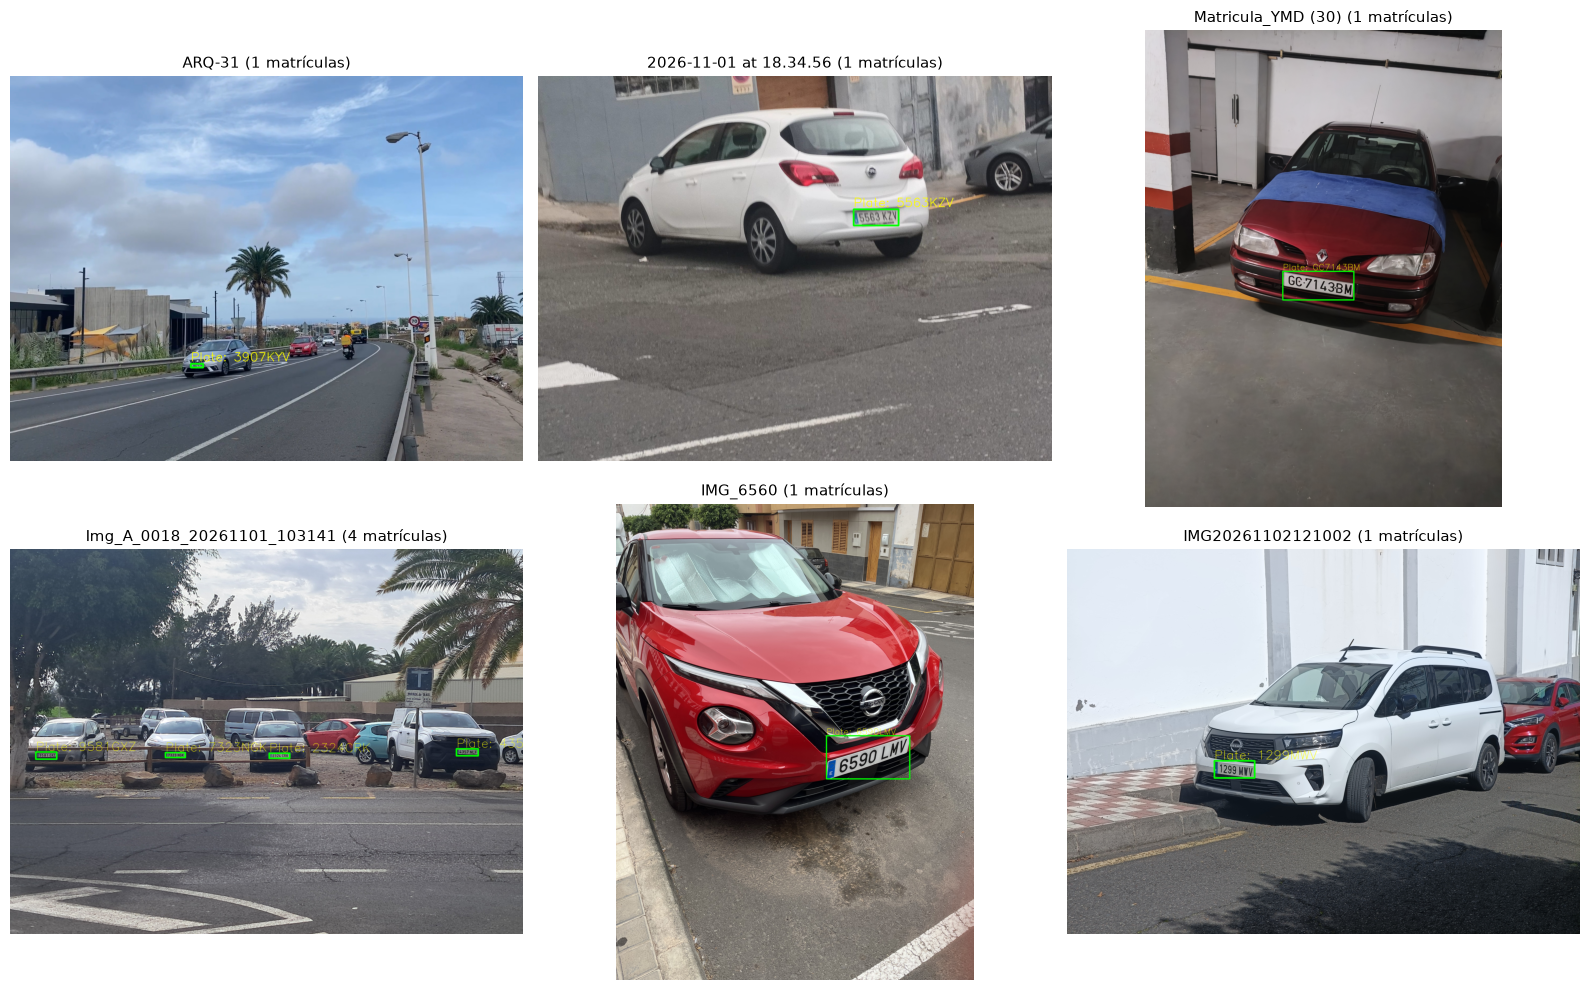

In [18]:
def visualize_dataset_samples(samples, num_samples=6, seed=SEED):
    """Muestra una cuadrícula de imágenes aleatorias con sus matrículas anotadas."""
    rng = random.Random(seed)
    # Seleccionamos muestras que contengan al menos una matrícula
    candidates = [s for s in samples if s["num_boxes"] > 0]
    selected = rng.sample(candidates, min(num_samples, len(candidates)))

    cols = 3
    rows = (len(selected) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, sample in enumerate(selected):
        img_bgr = cv2.imread(str(sample["image_path"]))
        if img_bgr is None:
            continue
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]

        for box, plate in zip(sample["boxes"], sample["plates"]):
            cx, cy, bw, bh = box
            x1 = int((cx - bw / 2) * w)
            y1 = int((cy - bh / 2) * h)
            x2 = int((cx + bw / 2) * w)
            y2 = int((cy + bh / 2) * h)

            # Dibujar rectángulo en verde
            cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), max(2, int(w * 0.003)))
            # Etiqueta de matrícula
            label = f"Plate: {plate}" if plate != "None" else "Plate"
            cv2.putText(img_rgb, label, (x1, max(y1 - 10, 25)),
                        cv2.FONT_HERSHEY_SIMPLEX, max(0.6, w * 0.0008), (255, 255, 0), 2)

        axes[i].imshow(img_rgb)
        axes[i].set_title(f"{sample['stem']} ({sample['num_boxes']} matrículas)", fontsize=11)
        axes[i].axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

visualize_dataset_samples(loader.samples, num_samples=6, seed=SEED)


In [20]:
def prepare_yolo_dataset(samples, output_dir, split_ratios=(0.75, 0.10, 0.15), seed=SEED, copy_files=False):
    """
    Divide aleatoriamente el dataset con una semilla y genera la estructura requerida por YOLO.
    Crea enlaces simbólicos a las imágenes (o copias) y escribe las etiquetas .txt correspondientes.
    """
    train_r, val_r, test_r = split_ratios
    assert abs(train_r + val_r + test_r - 1.0) < 1e-5, "Los ratios deben sumar 1.0"

    output_path = Path(output_dir).resolve()
    if output_path.exists():
        print(f"Limpiando directorio previo: {output_path}")
        shutil.rmtree(output_path)

    # Crear directorios
    splits = ["train", "val", "test"]
    for s in splits:
        (output_path / "images" / s).mkdir(parents=True, exist_ok=True)
        (output_path / "labels" / s).mkdir(parents=True, exist_ok=True)

    # Barajar con semilla reproducible
    shuffled_samples = list(samples)
    rng = random.Random(seed)
    rng.shuffle(shuffled_samples)

    total = len(shuffled_samples)
    n_train = int(total * train_r)
    n_val = int(total * val_r)
    n_test = total - n_train - n_val

    split_dict = {
        "train": shuffled_samples[:n_train],
        "val": shuffled_samples[n_train:n_train + n_val],
        "test": shuffled_samples[n_train + n_val:]
    }

    print("=" * 60)
    print(" DIVISIÓN DEL DATASET CON SEMILLA REPRODUCIBLE")
    print("=" * 60)
    for s in splits:
        pct = len(split_dict[s]) / total * 100
        total_boxes = sum(len(item["boxes"]) for item in split_dict[s])
        print(f"• {s.upper():<5}: {len(split_dict[s])} imágenes ({pct:.1f}%) | {total_boxes} matrículas")
    print("=" * 60)

    # Generar imágenes y etiquetas
    for split_name, items in split_dict.items():
        img_dest_dir = output_path / "images" / split_name
        lbl_dest_dir = output_path / "labels" / split_name

        for item in items:
            src_img = item["image_path"]
            dst_img = img_dest_dir / src_img.name

            # Enlace simbólico (ahorra espacio en disco) o copia
            if copy_files:
                shutil.copy2(src_img, dst_img)
            else:
                try:
                    os.symlink(src_img, dst_img)
                except OSError:
                    shutil.copy2(src_img, dst_img)

            # Escribir fichero de etiqueta YOLO (.txt)
            lbl_file = lbl_dest_dir / f"{item['stem']}.txt"
            lines = []
            for box in item["boxes"]:
                cx, cy, bw, bh = box
                # Clase 0 = license_plate
                lines.append(f"0 {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n")

            with open(lbl_file, "w", encoding="utf-8") as f:
                f.writelines(lines)

    # Crear data.yaml
    yaml_content = f"""# Ultralytics YOLO dataset configuration for License Plate Detection
path: {output_path.as_posix()}
train: images/train
val: images/val
test: images/test

# Clases
nc: 1
names: ['license_plate']
"""
    yaml_path = output_path / "data.yaml"
    with open(yaml_path, "w", encoding="utf-8") as f:
        f.write(yaml_content)

    print(f"✓ Configuración data.yaml creada exitosamente en: {yaml_path}")
    return yaml_path, split_dict


In [21]:
# Directorio de destino para el dataset preparado en formato YOLO
yolo_dataset_dir = (dataset_dir.absolute() / Path("yolo-training")).resolve()

# Ejecutar división 80/20
dataset_yaml_path, dataset_splits = prepare_yolo_dataset(
    samples=loader.samples,
    output_dir=yolo_dataset_dir,
    split_ratios=(0.75, 0.15, 0.10),
    seed=SEED,
    copy_files=False  # Usamos enlaces simbólicos para máxima rapidez y ahorro de espacio
)


 DIVISIÓN DEL DATASET CON SEMILLA REPRODUCIBLE
• TRAIN: 1804 imágenes (75.0%) | 2305 matrículas
• VAL  : 360 imágenes (15.0%) | 493 matrículas
• TEST : 242 imágenes (10.1%) | 335 matrículas
✓ Configuración data.yaml creada exitosamente en: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset/yolo-training/data.yaml


In [22]:
# ==========================================================
# SELECTOR DE TIPO DE MODELO YOLO
# ==========================================================
AVAILABLE_MODELS = {
    "nano":   "yolo11n.pt",   # Ultraligero, rápido, ideal para pruebas locales y CPU
    "small":  "yolo11s.pt",   # Buen equilibrio para detección precisa de matrículas
    "medium": "yolo11m.pt",   # Mayor capacidad
    "large":  "yolo11l.pt",   # Alta precisión
    "xlarge": "yolo11x.pt"    # Máxima capacidad
}

# Puedes cambiar la selección a 'nano', 'small', 'medium', etc.:
CHOSEN_MODEL_TYPE = "small"  # <--- SELECCIÓN DEL MODELO

model_weights = AVAILABLE_MODELS[CHOSEN_MODEL_TYPE]
print(f"Iniciando modelo YOLO: [{CHOSEN_MODEL_TYPE.upper()}] con pesos base: {model_weights}")

# Carga del modelo preentrenado base
model = YOLO(Path("yolo") / model_weights)
print("✓ Modelo cargado correctamente.")


Iniciando modelo YOLO: [SMALL] con pesos base: yolo11s.pt
✓ Modelo cargado correctamente.


In [ ]:
# Hiperparámetros de entrenamiento
EPOCHS = 120
BATCH_SIZE = 16
IMGSZ = 640
PATIENCE=30
PROJECT = Path("runs_plate")
EXPERIMENT_NAME = f"plate_detector_{IMGSZ}_BATCH_{BATCH_SIZE}_{CHOSEN_MODEL_TYPE}"

print(f"Lanzando entrenamiento en dispositivo: {DEVICE}")
print(f"Épocas: {EPOCHS} | Batch Size: {BATCH_SIZE} | Resolución: {IMGSZ}x{IMGSZ}")

Lanzando entrenamiento en dispositivo: 0
Épocas: 120 | Batch Size: 16 | Resolución: 640x640


In [ ]:
train_results = model.train(
    data=str(dataset_yaml_path),
    epochs=EPOCHS,
    batch=BATCH_SIZE,                # Tamaño de batch fijo y estable
    imgsz=IMGSZ,             # Mayor resolución para captar matrículas (o 960)
    device=DEVICE,
    amp=False,               # CRUCIAL: evita el desbordamiento numérico (val/cls_loss 36000) en Apple Silicon
    project=PROJECT,
    name=EXPERIMENT_NAME,
    seed=SEED,
    patience=PATIENCE,             # Aumentar paciencia para que no corte en época 11
    save=True,
    plots=True,
    verbose=True,
    exist_ok=True,
    workers=4,
    freeze=10,
    mosaic=0.0,              # Reducir mosaic para no destrozar objetos pequeños
    scale=0.2,
    hsv_v=0.4,
    hsv_s=0.6,
)

print("\n✓ ¡Entrenamiento completado!")


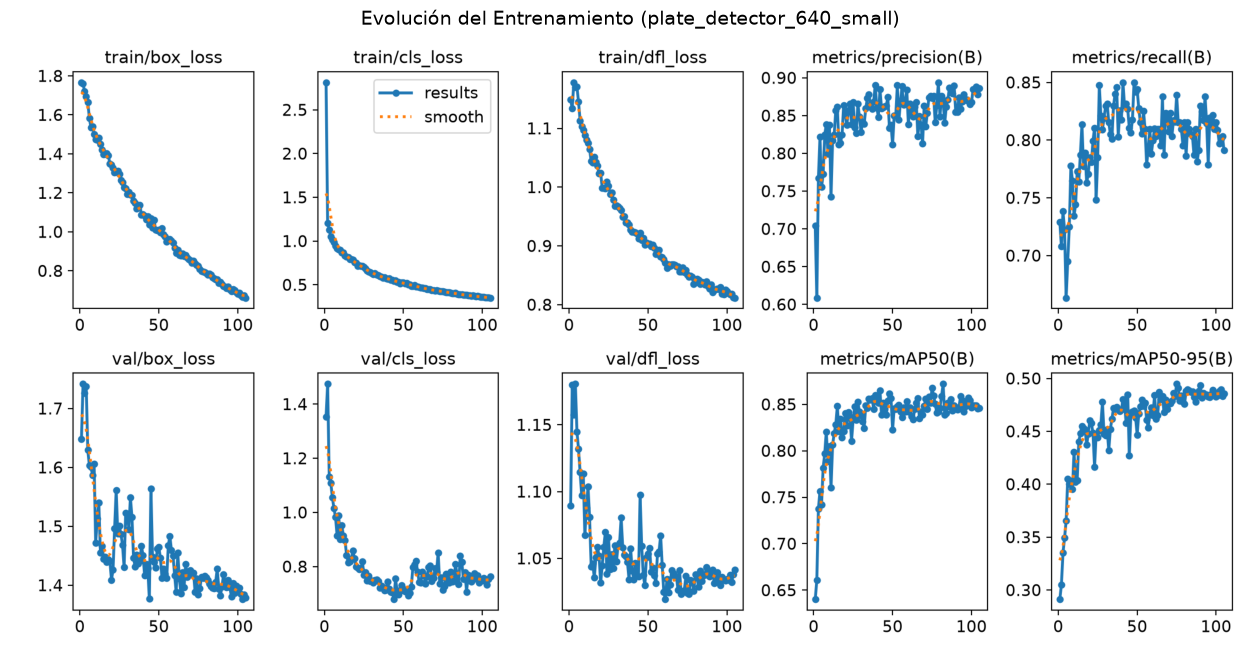

In [25]:
results_img_path = Path("runs/detect") / Path(PROJECT) / EXPERIMENT_NAME / "results.png"
if results_img_path.exists():
    plt.figure(figsize=(16, 10))
    res_img = cv2.imread(str(results_img_path))
    res_img = cv2.cvtColor(res_img, cv2.COLOR_BGR2RGB)
    plt.imshow(res_img)
    plt.axis("off")
    plt.title(f"Evolución del Entrenamiento ({EXPERIMENT_NAME})", fontsize=14)
    plt.show()
else:
    print(f"No se encontró el fichero de resultados en: {results_img_path}")


---
## 6. Evaluación y Métricas en el Conjunto de Test (15%)

Cargamos los mejores pesos obtenidos durante el entrenamiento (`weights/best.pt`) y realizamos la evaluación sobre el conjunto de test aislado (361 imágenes, el 15% reservado con la semilla).  
Obtenemos las métricas oficiales:
- **Precision (P)**: Proporción de matrículas predichas que son correctas.
- **Recall (R)**: Proporción de matrículas reales detectadas por el modelo.
- **mAP@50**: Precisión media calculada con umbral IoU de $0.50$.
- **mAP@50-95**: Precisión media acumulada calculada para umbrales IoU entre $0.50$ y $0.95$ con paso $0.05$.


In [26]:
best_weights_path = Path("runs/detect") / Path(PROJECT) / EXPERIMENT_NAME / "weights" / "best.pt"
if not best_weights_path.exists():
    print(f"Aviso: No se encontró {best_weights_path}, se utilizará el modelo en memoria.")
    trained_model = model
else:
    print(f"Cargando mejores pesos desde: {best_weights_path}")
    trained_model = YOLO(str(best_weights_path))

# Evaluación en el conjunto de TEST
print("Evaluando en el conjunto de TEST (15% aislado)...")
test_results = trained_model.val(
    data=str(dataset_yaml_path),
    split="test",
    device=DEVICE,
    plots=True
)

# Extracción de métricas
p = test_results.box.p[0] if len(test_results.box.p) > 0 else 0.0
r = test_results.box.r[0] if len(test_results.box.r) > 0 else 0.0
map50 = test_results.box.map50
map50_95 = test_results.box.map

print("=" * 60)
print(" MÉTRICAS OBTENIDAS EN EL CONJUNTO DE TEST")
print("=" * 60)
print(f"• Precision (P):       {p:.4f} ({p * 100:.2f}%)")
print(f"• Recall (R):          {r:.4f} ({r * 100:.2f}%)")
print(f"• mAP@50:              {map50:.4f} ({map50 * 100:.2f}%)")
print(f"• mAP@50-95:           {map50_95:.4f} ({map50_95 * 100:.2f}%)")
print("=" * 60)


Cargando mejores pesos desde: runs/detect/runs_plate/plate_detector_640_small/weights/best.pt
Evaluando en el conjunto de TEST (15% aislado)...
Ultralytics 8.4.202 🚀 Python-3.11.8 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3060 Ti, 7885MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 643.0±367.4 MB/s, size: 3015.2 KB)
val: Scanning /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset/yolo-training/labels/test... 242 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 242/242 65.3it/s 3.7s0.5ss
val: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset/yolo-training/images/test/20261031_190521.jpg: corrupt JPEG restored and saved
val: /home/skinnydevi/Development/computer-vision/image-dataset/prac4VC_dataset/yolo-training/images/test/20261031_190939.jpg: corrupt JPEG restored and saved
val: /home/skinnydevi/Development/computer-vision/image-dataset/prac

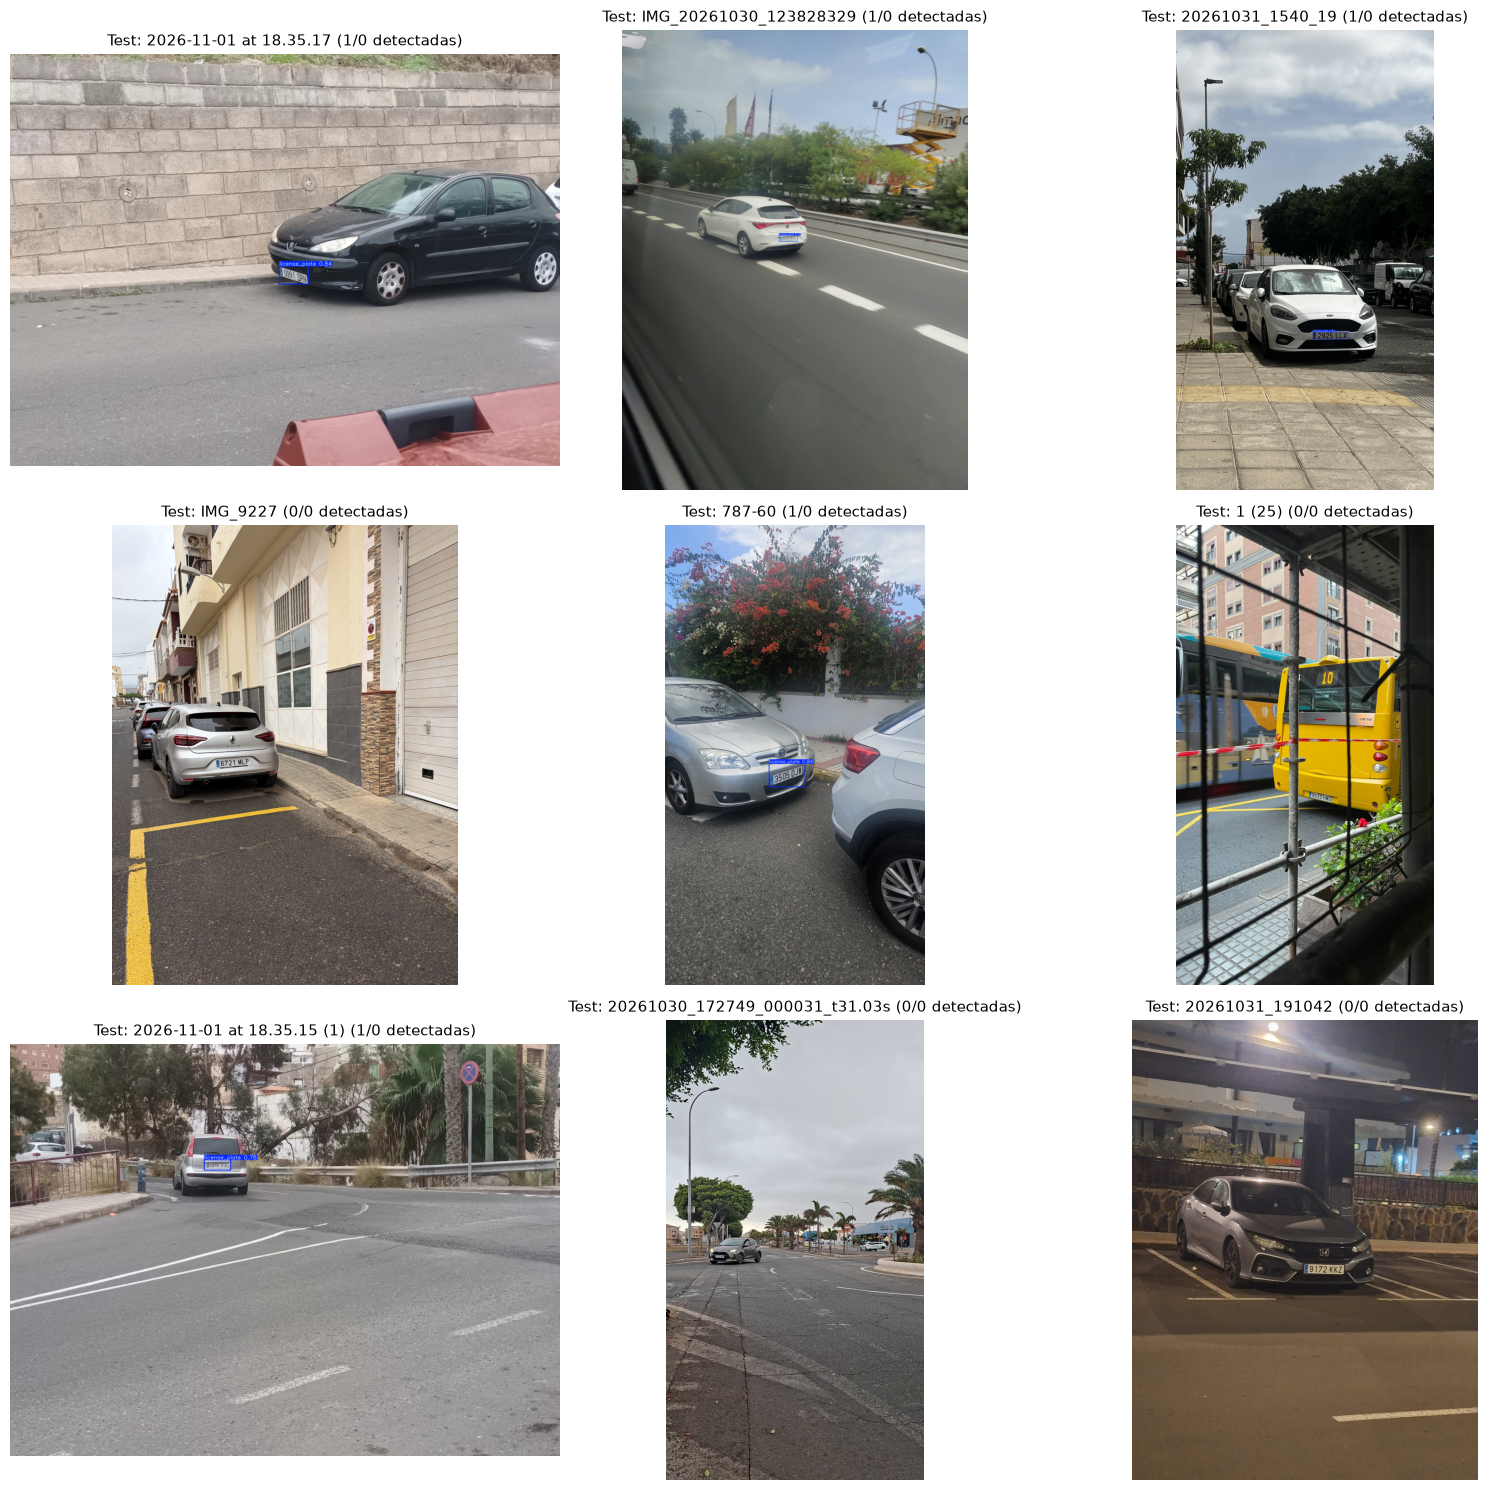

In [38]:
def visualize_test_predictions(trained_model, test_samples, num_samples=6, conf_threshold=0.35, seed=SEED):
    """Muestra predicciones cualitativas del modelo sobre imágenes del test split."""
    rng = random.Random(seed)
    selected = rng.sample(test_samples, min(num_samples, len(test_samples)))

    cols = 3
    rows = (len(selected) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, sample in enumerate(selected):
        img_path = sample["image_path"]
        results = trained_model.predict(source=str(img_path), conf=conf_threshold, verbose=False)
        
        # Imagen resultante anotada por YOLO
        annotated_bgr = results[0].plot(line_width=2, font_size=1)
        annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)

        num_det = len(results[0].boxes)
        axes[i].imshow(annotated_rgb)
        axes[i].set_title(f"Test: {sample['stem']} ({num_det}/{0} detectadas)", fontsize=11)
        axes[i].axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

visualize_test_predictions(trained_model, dataset_splits["test"], num_samples=9, conf_threshold=0.25, seed=SEED)


In [40]:
def process_video_plates(model, video_path, output_path, conf_threshold=0.35, max_frames=None, show_window=False):
    """
    Procesa un vídeo detectando y haciendo seguimiento de matrículas.
    Guarda el resultado en output_path y devuelve fotogramas clave para visualización.
    
    Parámetros:
        show_window: Si True, muestra una ventana OpenCV interactiva (pulsa ESC para detener).
    """
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"No se pudo abrir el vídeo: {video_path}")

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if max_frames:
        total_frames = min(total_frames, max_frames)

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(str(output_path), fourcc, fps, (width, height))

    print(f"Procesando vídeo: {video_path}")
    print(f"Dimensiones: {width}x{height} | FPS: {fps:.2f} | Fotogramas a procesar: {total_frames}")

    frame_count = 0
    detections_found = 0
    key_frames = []

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret or (max_frames and frame_count >= max_frames):
            break

        frame_count += 1

        # Realizar detección y seguimiento (persist=True para mantener IDs temporales)
        results = model.track(frame, conf=conf_threshold, persist=True, verbose=False)
        annotated_frame = frame.copy()

        if results and len(results[0].boxes) > 0:
            boxes = results[0].boxes
            detections_found += len(boxes)

            for box in boxes:
                x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
                conf = float(box.conf[0])
                track_id = int(box.id[0]) if box.id is not None else None

                # Dibujo del contenedor verde
                cv2.rectangle(annotated_frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
                
                label = f"Matricula {f'#{track_id}' if track_id else ''} {conf:.2f}"
                (lw, lh), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
                cv2.rectangle(annotated_frame, (x1, max(y1 - lh - 10, 0)), (x1 + lw + 6, max(y1, lh + 10)), (0, 255, 0), -1)
                cv2.putText(annotated_frame, label, (x1 + 3, max(y1 - 5, lh + 5)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)

            # Guardar fotograma clave de muestra (hasta 6)
            if len(key_frames) < 6 and (frame_count % 15 == 0 or len(key_frames) == 0):
                key_frames.append((frame_count, cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)))

        out.write(annotated_frame)

        if show_window:
            cv2.imshow("Deteccion y Seguimiento de Matriculas", annotated_frame)
            if cv2.waitKey(1) == 27:  # ESC para salir
                print("Interrumpido por el usuario.")
                break

        if frame_count % 30 == 0 or frame_count == total_frames:
            print(f"  -> Procesado fotograma {frame_count}/{total_frames} ({frame_count/total_frames*100:.1f}%)")

    cap.release()
    out.release()
    if show_window:
        cv2.destroyAllWindows()

    print(f"\n✓ Procesamiento completado.")
    print(f"✓ Total de detecciones de matrículas en el vídeo: {detections_found}")
    print(f"✓ Vídeo resultante guardado en: {output_path}")

    return key_frames

# Resolver ruta del vídeo
video_candidates = [
    Path("plate_test_video.mp4"),
    Path("P4a/plate_test_video.mp4"),
    Path("P4/P4a/plate_test_video.mp4"),
    Path("/Users/felixmv/Desktop/School/UNI/4to curso/VC/Entregas/P4/P4a/plate_test_video.mp4")
]
video_input_path = next(p.resolve() for p in video_candidates if p.exists())
video_output_path = Path("./yolo_plates_detected.mp4").resolve()

# Ejecutar procesador de vídeo
key_frames = process_video_plates(
    model=trained_model,
    video_path=video_input_path,
    output_path=video_output_path,
    conf_threshold=0.25,
    show_window=False  # Cambiar a True si se ejecuta en local con interfaz gráfica
)


Procesando vídeo: /home/skinnydevi/Development/computer-vision/P4/P4a/plate_test_video.mp4
Dimensiones: 1920x1080 | FPS: 25.00 | Fotogramas a procesar: 2832
  -> Procesado fotograma 30/2832 (1.1%)
  -> Procesado fotograma 60/2832 (2.1%)
  -> Procesado fotograma 90/2832 (3.2%)
  -> Procesado fotograma 120/2832 (4.2%)
  -> Procesado fotograma 150/2832 (5.3%)
  -> Procesado fotograma 180/2832 (6.4%)
  -> Procesado fotograma 210/2832 (7.4%)
  -> Procesado fotograma 240/2832 (8.5%)
  -> Procesado fotograma 270/2832 (9.5%)
  -> Procesado fotograma 300/2832 (10.6%)
  -> Procesado fotograma 330/2832 (11.7%)
  -> Procesado fotograma 360/2832 (12.7%)
  -> Procesado fotograma 390/2832 (13.8%)
  -> Procesado fotograma 420/2832 (14.8%)
  -> Procesado fotograma 450/2832 (15.9%)
  -> Procesado fotograma 480/2832 (16.9%)
  -> Procesado fotograma 510/2832 (18.0%)
  -> Procesado fotograma 540/2832 (19.1%)
  -> Procesado fotograma 570/2832 (20.1%)
  -> Procesado fotograma 600/2832 (21.2%)
  -> Procesado 

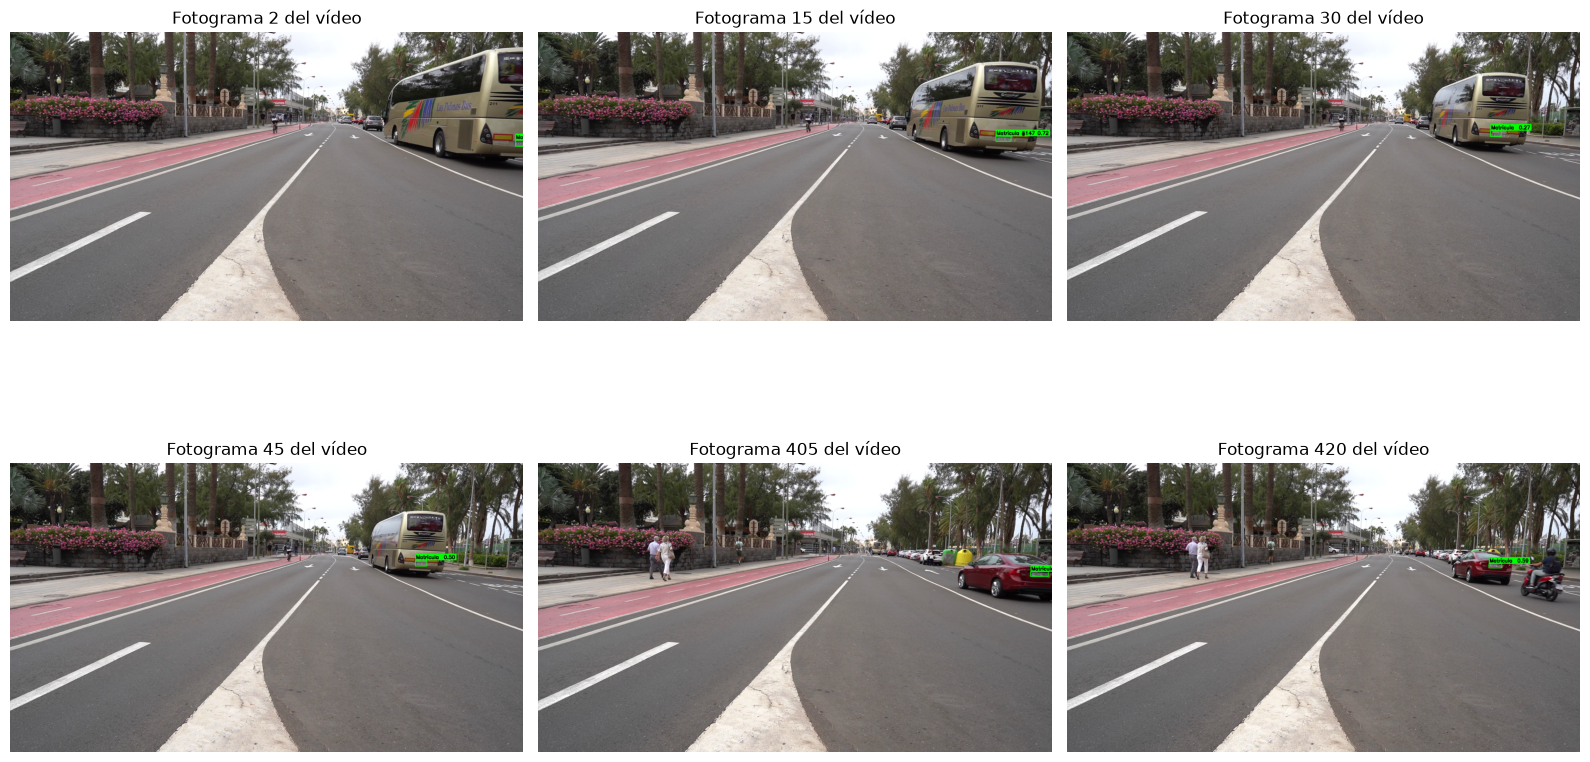

Ruta del vídeo generado: /home/skinnydevi/Development/computer-vision/P4/P4a/yolo_plates_detected.mp4


In [41]:
# Mostrar fotogramas clave extraídos del vídeo donde se detectaron matrículas
if key_frames:
    cols = 3
    rows = (len(key_frames) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, (fn, kf) in enumerate(key_frames):
        axes[i].imshow(kf)
        axes[i].set_title(f"Fotograma {fn} del vídeo", fontsize=12)
        axes[i].axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron detecciones en los fotogramas clave seleccionados.")

if video_output_path.exists():
    print(f"Ruta del vídeo generado: {video_output_path}")


In [ ]:
def run_dual_vehicle_and_plate_detector(vehicle_model, plate_model, video_path, num_frames=3, conf_thresh=0.35):
    """
    Aplica detector dual (Vehículos en AZUL + Matrículas en VERDE) sobre fotogramas del vídeo.
    """
    VEHICLE_CLASSES = [2, 3, 5, 7]  # car, motorcycle, bus, truck en COCO
    cap = cv2.VideoCapture(str(video_path))
    
    frames_shown = 0
    cap.set(cv2.CAP_PROP_POS_FRAMES, 30)  # Empezar a partir del fotograma 30

    fig, axes = plt.subplots(num_frames, 1, figsize=(14, 6 * num_frames))
    if num_frames == 1:
        axes = [axes]

    while cap.isOpened() and frames_shown < num_frames:
        ret, frame = cap.read()
        if not ret:
            break

        # 1. Detección de vehículos con modelo general
        veh_results = vehicle_model(frame, classes=VEHICLE_CLASSES, conf=conf_thresh, verbose=False)
        
        # 2. Detección de matrículas con nuestro modelo especializado
        plate_results = plate_model(frame, conf=conf_thresh, verbose=False)

        combined_frame = frame.copy()

        # Dibujar vehículos en AZUL
        for box in veh_results[0].boxes:
            x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
            cls_name = veh_results[0].names[int(box.cls[0])]
            conf = float(box.conf[0])
            cv2.rectangle(combined_frame, (x1, y1), (x2, y2), (255, 100, 0), 2)
            cv2.putText(combined_frame, f"{cls_name} {conf:.2f}", (x1, max(y1 - 8, 20)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 150, 0), 2)

        # Dibujar matrículas en VERDE / AMARILLO
        for box in plate_results[0].boxes:
            x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
            conf = float(box.conf[0])
            cv2.rectangle(combined_frame, (x1, y1), (x2, y2), (0, 255, 0), 3)
            cv2.putText(combined_frame, f"MATRICULA {conf:.2f}", (x1, max(y1 - 8, 20)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

        rgb_frame = cv2.cvtColor(combined_frame, cv2.COLOR_BGR2RGB)
        axes[frames_shown].imshow(rgb_frame)
        axes[frames_shown].set_title(f"Detección Combinada: Vehículos (Azul) y Matrículas (Verde)", fontsize=13)
        axes[frames_shown].axis("off")
        frames_shown += 1

        # Avanzar 30 fotogramas para mostrar momentos distintos
        for _ in range(30):
            cap.read()

    cap.release()
    plt.tight_layout()
    plt.show()

# Cargar modelo base COCO para vehículos
general_model = YOLO("yolo11n.pt")

# Ejecutar demostración dual
run_dual_vehicle_and_plate_detector(
    vehicle_model=general_model,
    plate_model=trained_model,
    video_path=video_input_path,
    num_frames=3,
    conf_thresh=0.35
)
